### Mount Brown South accumulation record - density correction

In [16]:
#packages
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from datetime import datetime


In [22]:
# Load density data from csv
# corrected_depth is the mid point depth of each 1 m core section
# q_core_log column is the quality control column using the core log
# cores with material missing or core breaks are marked with 0, and "good" cores are marked with 1
data = pd.read_csv('data/mbs_depth_densities_q.csv')
data

,Bag #,Bag bottom depth (m),Bag length (cm),corrected_depth,density,quality,q2,q3,q_core_log
0,MBS1718-5,5.0,92.0,4.54,508.536012,1.0,1,1,1
1,MBS1718-6,6.0,100.0,5.50,511.018055,1.0,1,1,1
2,MBS1718-7,7.0,100.0,6.50,516.173806,1.0,1,1,0
3,MBS1718-8,8.0,100.0,7.50,533.536256,1.0,1,1,0
4,MBS1718-9,9.0,100.0,8.50,552.878153,1.0,1,1,1
...,...,...,...,...,...,...,...,...,...
286,MBS1718-291,291.0,100.0,290.50,903.987318,0.0,0,0,0
287,MBS1718-292,292.0,100.0,291.50,911.925542,1.0,0,0,0
288,MBS1718-293,293.0,100.0,292.50,909.279468,0.0,0,0,0
289,MBS1718-294,294.0,100.0,293.50,906.633393,0.0,0,0,1


In [23]:
# drop rows where density is 0, because 0 represents missing data
data = data.loc[data['density'] != 0].copy()

In [5]:

def van_ommen_model(d, cf, kf, c0, r, db, cs):
    """
    Calculates density as a function of depth, by fitting a line to measured density.
    d: array of depths
    cf, kf, c0, r, db, cs: constants to be calculated
    This function is used with curve_fit
    Form of the equation is from Van Ommen et al 1999
    """

    rho_i = 917.0
    ratio = -(c0 + r * db) / cs
    ks = -db / np.log(ratio) if ratio > 0 and ratio < 1 else 1e6
    rho = np.zeros_like(d)
    for i, depth in enumerate(d):
        if depth < db:
            rho[i] = rho_i - cf * np.exp(-depth / kf) + (c0 + r * depth)
        else:
            rho[i] = rho_i - cf * np.exp(-depth / kf) - cs * np.exp(-depth / ks)

    return rho

In [6]:
def q_controlled(df, q_col):

# this removes the rows where the value of the q control column is zero (ie it keeps the rows that passes the q control)
    df = df.loc[~(df[q_col] == 0)]
    depths = df["corrected_depth"].values
    densities = df["density"].values
    return depths, densities

In [7]:
def q_controlled_removed(df, q_col):

# this keeps the rows where the value of the q control column is zero (ie it keeps the rows that failed the q control)
    df = df.loc[(df[q_col] == 0)]
    depths = df["corrected_depth"].values
    densities = df["density"].values
    return depths, densities

In [24]:
# make vectors of depths and densities, depending on whether they pass or fail the quality control

q_control_column = "q_core_log"
depths = q_controlled(data, q_control_column)[0]
densities = q_controlled(data, q_control_column)[1]

depths_removed = q_controlled_removed(data, q_control_column)[0]
densities_removed = q_controlled_removed(data, q_control_column)[1]


In [11]:

# initial_guess = [cf, kf, c0, r, db, cs]
initial_guess = [150, 8, -350, 4, 60, 600]
bounds = ([0, 0.1, -1000, -10, 5, 1], [1000, 200, 1000, 10, 200, 2000])

# fit the model
popt, pcov = curve_fit(van_ommen_model, depths, densities,
                        p0=initial_guess, bounds=bounds)

In [12]:
# Extract fitted parameters and compute ks
cf_fit, kf_fit, c0_fit, r_fit, db_fit, cs_fit = popt
ratio_fit = -(c0_fit + r_fit * db_fit) / cs_fit
ks_fit = -db_fit / np.log(ratio_fit) if ratio_fit > 0 and ratio_fit < 1 else np.nan


# Compute uncertainties from covariance matrix
perr = np.sqrt(np.diag(pcov))
cf_err, kf_err, c0_err, r_err, db_err, cs_err = perr

In [13]:
# save fitted params to list for use in IE depth calculations
fitted_params_list = (cf_fit, kf_fit, c0_fit, r_fit, db_fit, cs_fit, ks_fit)

In [14]:
# Compute R² and residuals
fitted_densities = van_ommen_model(depths, *popt)
residuals = densities - fitted_densities
ss_res = np.sum(residuals**2)
ss_tot = np.sum((densities - np.mean(densities))**2)
r_squared = 1 - (ss_res / ss_tot)

In [25]:
# Prepare results DataFrame
results = pd.DataFrame({
    'Parameter': ['cf', 'kf', 'c0', 'r', 'db', 'cs', 'ks', 'R²'],
    'Initial Guess': initial_guess + [np.nan, np.nan],
    'Estimate': [cf_fit, kf_fit, c0_fit, r_fit, db_fit, cs_fit, ks_fit, r_squared],
    'Uncertainty': [cf_err, kf_err, c0_err, r_err, db_err, cs_err, np.nan, np.nan]
})


# Save with timestamp
timestamp = datetime.now().strftime('%Y%m%d_%H%M')
filename = f'van_ommen_fit_results_{q_control_column}_{timestamp}.csv'
results.to_csv(filename, index=False)


print(f"Results saved to {filename}")
print(results)

Results saved to van_ommen_fit_results_q_core_log_20260821_1358.csv
  Parameter  Initial Guess    Estimate   Uncertainty
0        cf          150.0  118.879182  1.392814e+01
1        kf            8.0    8.227364  2.365349e+00
2        c0         -350.0 -359.562204  9.212283e+00
3         r            4.0    3.768971  1.834572e-01
4        db           60.0   62.943953  2.224115e+06
5        cs          600.0  850.675961  6.177741e+01
6        ks            NaN   32.456661           NaN
7        R²            NaN    0.996886           NaN


In [26]:
# add fitted_density column to dataframe
data["fitted_density"] = van_ommen_model(data["corrected_depth"], *popt)

In [19]:
# make an array of depths and densities for plotting
depths_array = np.arange(0.0, 297.0, 1)
fitted_densities_array = van_ommen_model(depths_array, *popt)

In [20]:
# read in core density measurements from MBS 1998
mbs_1998 = pd.read_csv("data/mbs_1998_density.csv")
mbs_1998

,Core section,Length,Bottom,corrected_depth,density,Error
0,MBS-1,1.0050,1.0050,0.50250,471.3258,33.203
1,MBS-2,0.7900,1.7950,1.40000,457.0849,27.993
2,MBS-3,1.0160,2.8110,2.30300,436.8881,7.579
3,MBS-4,0.9300,3.7410,3.27600,470.1260,13.441
4,MBS-5,1.0100,4.7510,4.24600,507.9544,10.054
5,MBS-6,1.0095,5.7605,5.25575,521.5218,6.202
6,MBS-7,0.9100,6.6705,6.21550,508.9562,8.757
7,MBS-8,0.9300,7.6005,7.13550,559.5010,67.806
8,MBS-9,0.9890,8.5895,8.09500,556.5936,9.998
9,MBS-10,0.7050,9.2945,8.94200,549.2683,8.803


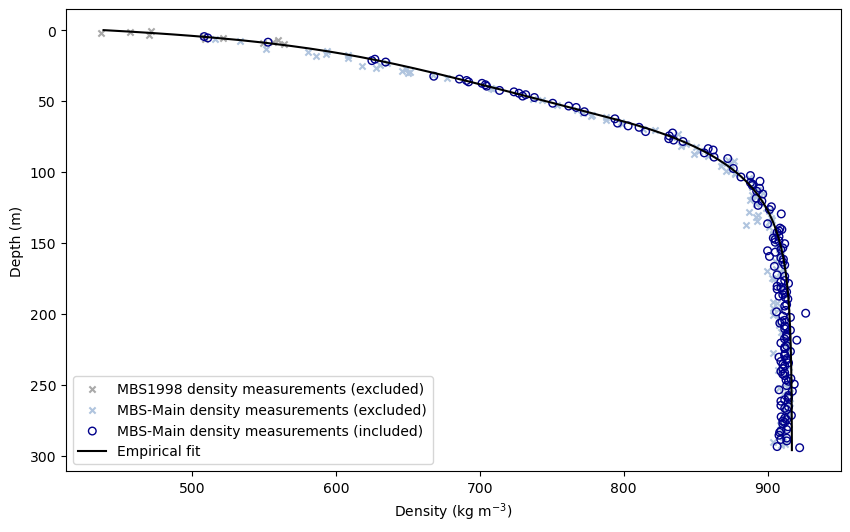

In [21]:
# plot denisty profile
timestamp = datetime.now().strftime('%Y%m%d_%H%M')
fig, ax = plt.subplots(figsize=(10,6))
ax.scatter(mbs_1998["density"], mbs_1998["corrected_depth"], alpha=1, color="darkgrey", label= "MBS1998 density measurements (excluded)", s=20, marker="x")
ax.scatter(densities_removed, depths_removed, color='lightsteelblue', alpha=1, label = "MBS-Main density measurements (excluded)", s=20, marker="x")
ax.scatter(densities, depths, color='black', alpha=1, label="MBS-Main density measurements (included)", s=30, edgecolor="darkblue", facecolors="none")
ax.plot(fitted_densities_array, depths_array, color='black', label='Empirical fit')
ax.invert_yaxis()
ax.set_xlabel('Density (kg m$^{-3}$)')
ax.set_ylabel('Depth (m)')
ax.legend(loc = "lower left")
# fig.savefig(f'figs/density_profile_{timestamp}.pdf')

In [31]:
# read in chronology spreadsheet for mbs-main
depth_age_main = pd.read_csv('data/mbs_main_chronology.csv')
# remove rows with NaN
depth_age_main = depth_age_main.dropna(subset=['layer_thickness'])
depth_age_main
# depth_corrected is the mid point depth of each year

,Depth,Horizon_Type,Year,depth_corrected,layer_thickness
1,4.562,1,2008,4.4135,0.297
2,5.081,1,2007,4.8215,0.519
3,5.496,2,2006,5.2885,0.415
4,5.926,1,2005,5.7110,0.430
5,6.421,1,2004,6.1735,0.495
...,...,...,...,...,...
1132,293.732,1,877,293.5410,0.382
1133,294.013,1,876,293.8725,0.281
1134,294.319,1,875,294.1660,0.306
1135,294.501,1,874,294.4100,0.182


In [28]:
# read in chronology spreadsheet for mbs-charlie
charlie_chronology = pd.read_csv("data/mbs_charlie_chronology.csv")
charlie_chronology

,Depth,Horizon_Type,Year,depth_corrected,layer_thickness
0,0.588,1,2017,0.2940,0.588
1,1.044,1,2016,0.8160,0.456
2,1.717,1,2015,1.3805,0.673
3,2.024,1,2014,1.8705,0.307
4,2.444,1,2013,2.2340,0.420
5,2.984,1,2012,2.7140,0.540
6,3.525,1,2011,3.2545,0.541
7,3.810,2,2010,3.6675,0.285
8,4.246,1,2009,4.0280,0.436
9,4.972,1,2008,4.6090,0.726


In [32]:
# add column for vO model fitted densities for mbs main
depth_age_main["fitted_densities"] = van_ommen_model(depth_age_main["depth_corrected"], *popt)

# add column for vO model fitted densities for charlie
charlie_chronology["fitted_densities"] = van_ommen_model(charlie_chronology["depth_corrected"], *popt)

In [33]:
# make composite record using mbs main to and including 1989 and charlie from 1990
depth_age_1990 = depth_age_main[depth_age_main['Year'] <1990]
charlie_accum_1990 = charlie_chronology[charlie_chronology["Year"]>1989]
composite_accum = pd.concat([charlie_accum_1990, depth_age_1990], ignore_index=True)
composite_accum

,Depth,Horizon_Type,Year,depth_corrected,layer_thickness,fitted_densities
0,0.588,1,2017,0.2940,0.588,443.839763
1,1.044,1,2016,0.8160,0.456,452.858835
2,1.717,1,2015,1.3805,0.673,462.125156
3,2.024,1,2014,1.8705,0.307,469.783619
4,2.444,1,2013,2.2340,0.420,475.246751
...,...,...,...,...,...,...
1140,293.732,1,877,293.5410,0.382,916.899546
1141,294.013,1,876,293.8725,0.281,916.900567
1142,294.319,1,875,294.1660,0.306,916.901462
1143,294.501,1,874,294.4100,0.182,916.902200


In [34]:
# calculate IE layer thickness and add as a column
composite_accum["IE_layer_thickness"] = composite_accum["layer_thickness"]*composite_accum["fitted_densities"]/917
composite_accum

,Depth,Horizon_Type,Year,depth_corrected,layer_thickness,fitted_densities,IE_layer_thickness
0,0.588,1,2017,0.2940,0.588,443.839763,0.284600
1,1.044,1,2016,0.8160,0.456,452.858835,0.225195
2,1.717,1,2015,1.3805,0.673,462.125156,0.339161
3,2.024,1,2014,1.8705,0.307,469.783619,0.157278
4,2.444,1,2013,2.2340,0.420,475.246751,0.217670
...,...,...,...,...,...,...,...
1140,293.732,1,877,293.5410,0.382,916.899546,0.381958
1141,294.013,1,876,293.8725,0.281,916.900567,0.280970
1142,294.319,1,875,294.1660,0.306,916.901462,0.305967
1143,294.501,1,874,294.4100,0.182,916.902200,0.181981


In [35]:
def depth_ie_constants( cf, kf, c0, r, db, cs, ks):

    # calculates the constants after integrating the density relationship to get IE depth
    # Jong et al 2022 shows the formula for calculating IE depth, and I replicated this here. 

    rho_i = 917.0
    z=0 

    depth_1 = z + ((cf * kf)/rho_i)*np.exp(-z/kf) +(c0/rho_i)*z + (r/(2*rho_i))*z**2
    depth_2 = z + ((cf * kf)/rho_i)*np.exp(-z/kf) + ((cs*ks)/rho_i)*np.exp(-z/ks)

    
    
    c1 = -depth_1

    z=db
    depth_1 = z + ((cf * kf)/rho_i)*np.exp(-z/kf) +(c0/rho_i)*z + (r/(2*rho_i))*z**2
    depth_2 = z + ((cf * kf)/rho_i)*np.exp(-z/kf) + ((cs*ks)/rho_i)*np.exp(-z/ks)

    # for continuity at z= db

    c2 = -depth_2 + depth_1 + c1

    return c1, c2

In [36]:
def ice_equiv_depths(d, cf, kf, c0, r, db, cs, ks):


    # this uses the integral of the denisty-depth relationship to get the ice equivalent depths
    rho_i = 917.0

    c1, c2 = depth_ie_constants(cf, kf, c0, r, db, cs, ks)


    z_ie = np.zeros_like(d)

    # these equations come from integrating the density-depth relationship, like in Jong et al 2022
    # I don't think I actually need to do the enumerate thing but it works this way so whatever
    for i, depth in enumerate(d):
        if depth < db:
            z_ie[i] = depth + ((cf * kf)/rho_i)*np.exp(-depth/kf) +(c0/rho_i)*depth + (r/(2*rho_i))*depth**2 + c1
        else:
            z_ie[i] = depth + ((cf * kf)/rho_i)*np.exp(-depth/kf) + ((cs*ks)/rho_i)*np.exp(-depth/ks) + c2

    return z_ie

In [37]:
# make IE depth column
composite_accum["IE_depth"] = ice_equiv_depths(composite_accum["depth_corrected"], *fitted_params_list)
composite_accum

,Depth,Horizon_Type,Year,depth_corrected,layer_thickness,fitted_densities,IE_layer_thickness,IE_depth
0,0.588,1,2017,0.2940,0.588,443.839763,0.284600,0.141457
1,1.044,1,2016,0.8160,0.456,452.858835,0.225195,0.396700
2,1.717,1,2015,1.3805,0.673,462.125156,0.339161,0.678355
3,2.024,1,2014,1.8705,0.307,469.783619,0.157278,0.927353
4,2.444,1,2013,2.2340,0.420,475.246751,0.217670,1.114665
...,...,...,...,...,...,...,...,...
1140,293.732,1,877,293.5410,0.382,916.899546,0.381958,271.609468
1141,294.013,1,876,293.8725,0.281,916.900567,0.280970,271.940932
1142,294.319,1,875,294.1660,0.306,916.901462,0.305967,272.234400
1143,294.501,1,874,294.4100,0.182,916.902200,0.181981,272.478374


In [38]:
# save to CSV
composite_accum.to_csv("data/mbs_composite_chronology_IE.csv", index=False)